# Цены газа и нефти — MOEX AlgoPack

Чистые графики цен фьючерсов **NG** (природный газ, USD/MMBtu) и **BR** (Brent, USD/bbl)
по данным MOEX AlgoPack, обработанным через `exchange`.

### Что здесь показано и почему именно так

Вендор отдаёт ряд, **склеенный по ближайшей экспирации и не скорректированный**: на каждом
переходе между контрактами в цене остаётся скачок. По NG медианный скачок **+384 б.п.**, и 95%
переходов превышают 100 б.п. — сырой ряд за 2020–2026 вырастает на 63%, тогда как торгуемая
доходность падает на 77%. Разница в 140 процентных пунктов создана исключительно склейкой.

Отсюда разделение ролей, и каждый график отвечает ровно на один вопрос тем рядом, который на него
отвечает честно:

| § | Вопрос | Ряд |
|---|---|---|
| 1–2 | Сколько стоил инструмент? | **Котировки как есть** — цена ближнего контракта, реальные уровни |
| 3 | Что заработала бы позиция? | **Торгуемая доходность** — бары роллов исключены |
| 4 | Чего стоит сырой ряд? | Оба, рядом |

Так на графике с подписью «цена» не окажется пересчитанных уровней: back-adjustment умножает
историю на накопленный коэффициент роллов (для NG это ×8.4 в начале выборки), и пик 2022 года
превратился бы в $31/MMBtu, которых рынок никогда не видел.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

from exchange.data.moex import moex_continuous
from exchange.data.prespliced import splice_artefact

# Данные: репозиторный путь, затем локальная копия.
CANDIDATES = [
    Path.cwd().parents[1] / "data" / "raw" / "moex_algopack",
    Path.cwd().parent / "data" / "raw" / "moex_algopack",
    Path("/home/user/moex"),
]
DATA = next((p for p in CANDIDATES if p.is_dir()), None)
if DATA is None:
    raise FileNotFoundError(f"не найден каталог AlgoPack; искал: {[str(p) for p in CANDIDATES]}")
print("данные:", DATA)

данные: /home/user/moex


In [2]:
# --- Палитра и стиль -------------------------------------------------------
# Валидированная палитра: слот 1 (синий) и слот 2 (оранжевый).
# Проверено validate_palette.js: CVD ΔE 24.7, normal-vision ΔE 33.6, контраст ≥ 3:1.
SERIES_1   = "#2a78d6"   # NG
SERIES_2   = "#eb6834"   # BR
SURFACE    = "#fcfcfb"
INK        = "#0b0b0b"
INK_2      = "#52514e"
MUTED      = "#898781"
GRID       = "#e1e0d9"
AXIS       = "#c3c2b7"

mpl.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.linewidth": 0.8,
    "axes.edgecolor": AXIS,
    "lines.linewidth": 2.0,          # 2px линия
    "lines.solid_capstyle": "round",
    "lines.solid_joinstyle": "round",
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "figure.dpi": 130,
})


def frame(ax, title, subtitle="", ylabel="", unit=""):
    """Сетка-хэрлайн, убранные лишние рамки, подписи в чернилах текста."""
    ax.grid(True, axis="y", color=GRID, linewidth=0.8, linestyle="-", zorder=0)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.set_title(title, color=INK, fontsize=12.5, fontweight="semibold", loc="left", pad=16)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=INK_2, fontsize=9.5, va="bottom")
    ax.set_ylabel(ylabel, color=INK_2, fontsize=9.5)
    if unit:
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}{unit}"))
    ax.tick_params(length=3, color=AXIS)


def end_label(ax, series, color, text=None):
    """Значение на конце линии — подпись в чернилах текста, цвет несёт сама линия."""
    x, y = series.index[-1], float(series.iloc[-1])
    ax.plot([x], [y], marker="o", markersize=5, color=color, zorder=5,
            markeredgecolor=SURFACE, markeredgewidth=1.5)
    ax.annotate(text or f"{y:,.2f}", xy=(x, y), xytext=(8, 0),
                textcoords="offset points", va="center", color=INK_2,
                fontsize=9.5, fontweight="semibold")

In [3]:
# --- Загрузка --------------------------------------------------------------
def daily(series):
    """Дневные бары из часовых, с сохранением флага ролла."""
    bars = series.bars.resample("1D").agg(
        {"open": "first", "high": "max", "low": "min",
         "close": "last", "volume": "sum", "is_roll": "max"}
    ).dropna(subset=["close"])
    bars["is_roll"] = bars["is_roll"].astype(bool)
    return bars


panels = {}
for ticker in ("ng", "br"):
    raw = moex_continuous(DATA, ticker, "60m", adjustment="none")
    adjusted = moex_continuous(DATA, ticker, "60m", adjustment="ratio")
    panels[raw.root] = {
        "raw": daily(raw), "adjusted": daily(adjusted),
        "artefact": splice_artefact(raw), "series": raw,
    }

summary = pd.DataFrame({
    root: {
        "бар (дневных)": len(p["adjusted"]),
        "с": p["adjusted"].index[0].strftime("%Y-%m-%d"),
        "по": p["adjusted"].index[-1].strftime("%Y-%m-%d"),
        "контрактов": len(p["series"].provenance.contracts_used),
        "роллов": p["artefact"]["n_rolls"],
        "медианный скачок, б.п.": round(p["artefact"]["median_gap_bps"], 1),
        "артефакт склейки": f"{p['artefact']['splice_artefact']:+.1%}",
        "последняя цена": round(float(p["adjusted"]["close"].iloc[-1]), 3),
    }
    for root, p in panels.items()
})
summary

12:38:44 INFO    exchange.data.moex | ng/60m: 25854 bars, 2020-02-03 07:00:00+00:00..2026-10-03 15:00:00+00:00, 81 contract(s)


12:38:44 INFO    exchange.data.prespliced | NG: 25854 bars, 81 contract(s), 80 roll(s), adjustment=none


12:38:44 INFO    exchange.data.moex | ng/60m: 25854 bars, 2020-02-03 07:00:00+00:00..2026-10-03 15:00:00+00:00, 81 contract(s)


12:38:44 INFO    exchange.data.prespliced | NG: 25854 bars, 81 contract(s), 80 roll(s), adjustment=ratio


12:38:45 INFO    exchange.data.moex | br/60m: 53630 bars, 2011-12-19 06:00:00+00:00..2026-10-03 15:00:00+00:00, 177 contract(s)


12:38:45 INFO    exchange.data.prespliced | BR: 53630 bars, 177 contract(s), 176 roll(s), adjustment=none


12:38:45 INFO    exchange.data.moex | br/60m: 53630 bars, 2011-12-19 06:00:00+00:00..2026-10-03 15:00:00+00:00, 177 contract(s)


12:38:45 INFO    exchange.data.prespliced | BR: 53630 bars, 177 contract(s), 176 roll(s), adjustment=ratio


,NG,BR
бар (дневных),1782,3828
с,2020-02-03,2011-12-19
по,2026-10-03,2026-10-03
контрактов,81,177
роллов,80,176
"медианный скачок, б.п.",384.0,-31.0
артефакт склейки,+139.7%,+16.1%
последняя цена,3.043,102.44


## 1. Природный газ — NG

Цена ближнего фьючерса MOEX в долларах за MMBtu — те уровни, которые действительно печатались.
Один ряд, поэтому легенда не нужна: его называет заголовок, а последнее значение подписано прямо
на линии.

Ступени на переходах между контрактами здесь присутствуют и это правильно: цена ближнего
контракта в день ролла меняется потому, что сменился инструмент. Торговать эту ступень нельзя —
см. §3 и §4.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


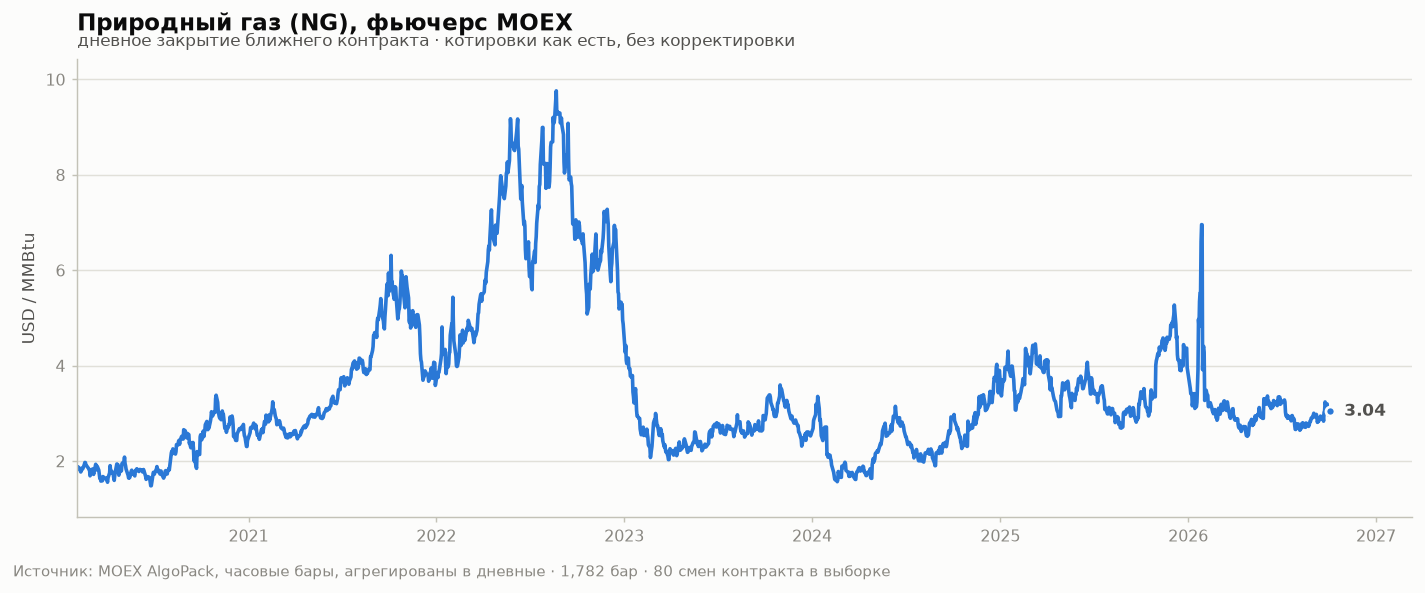

In [4]:
ng_quoted = panels["NG"]["raw"]["close"]      # котировки как есть
ng = panels["NG"]["adjusted"]["close"]        # торгуемые доходности (нужны в §3–4)

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(ng_quoted.index, ng_quoted.to_numpy(), color=SERIES_1)
frame(ax, "Природный газ (NG), фьючерс MOEX",
      "дневное закрытие ближнего контракта · котировки как есть, без корректировки",
      ylabel="USD / MMBtu")
end_label(ax, ng_quoted, SERIES_1)
ax.set_xlim(ng_quoted.index[0], ng_quoted.index[-1] + pd.Timedelta(days=160))
ax.margins(y=0.08)
fig.text(0.008, -0.02, "Источник: MOEX AlgoPack, часовые бары, агрегированы в дневные · "
         f"{len(ng_quoted):,} бар · {panels['NG']['artefact']['n_rolls']} смен контракта в выборке",
         color=MUTED, fontsize=8.5)
plt.tight_layout()
plt.show()

## 2. Нефть Brent — BR

Та же конструкция, история почти втрое длиннее: с декабря 2011 года. Brent в основном в
бэквордации, поэтому её ступени на роллах мельче и разнонаправленны — медианная −31 б.п. против
+384 б.п. у газа.

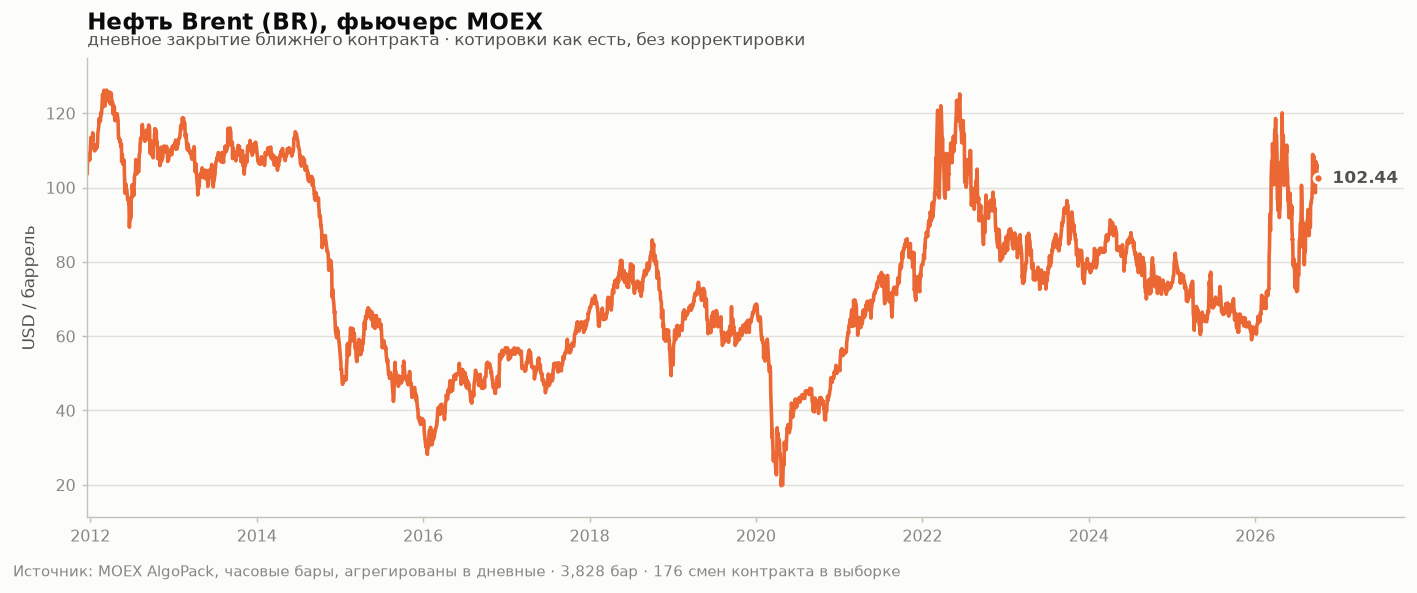

In [5]:
br_quoted = panels["BR"]["raw"]["close"]
br = panels["BR"]["adjusted"]["close"]

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(br_quoted.index, br_quoted.to_numpy(), color=SERIES_2)
frame(ax, "Нефть Brent (BR), фьючерс MOEX",
      "дневное закрытие ближнего контракта · котировки как есть, без корректировки",
      ylabel="USD / баррель")
end_label(ax, br_quoted, SERIES_2)
ax.set_xlim(br_quoted.index[0], br_quoted.index[-1] + pd.Timedelta(days=380))
ax.margins(y=0.08)
fig.text(0.008, -0.02, "Источник: MOEX AlgoPack, часовые бары, агрегированы в дневные · "
         f"{len(br_quoted):,} бар · {panels['BR']['artefact']['n_rolls']} смен контракта в выборке",
         color=MUTED, fontsize=8.5)
plt.tight_layout()
plt.show()

## 3. Что заработала бы позиция

Цены в разных единицах (USD/MMBtu против USD/баррель), поэтому **двух шкал на одном графике быть
не должно** — это самая частая ошибка в финансовой графике: наклоны двух линий становятся
несопоставимыми, а их пересечения — случайными артефактами выбора масштаба.

Корректный способ сравнить — привести оба ряда к 100 на общем старте. Тогда ось одна и означает
одно и то же: накопленную **торгуемую** доходность непрерывно удерживаемой длинной позиции, из
которой исключены бары роллов. Это уже не цена, поэтому и подписана она не как цена.

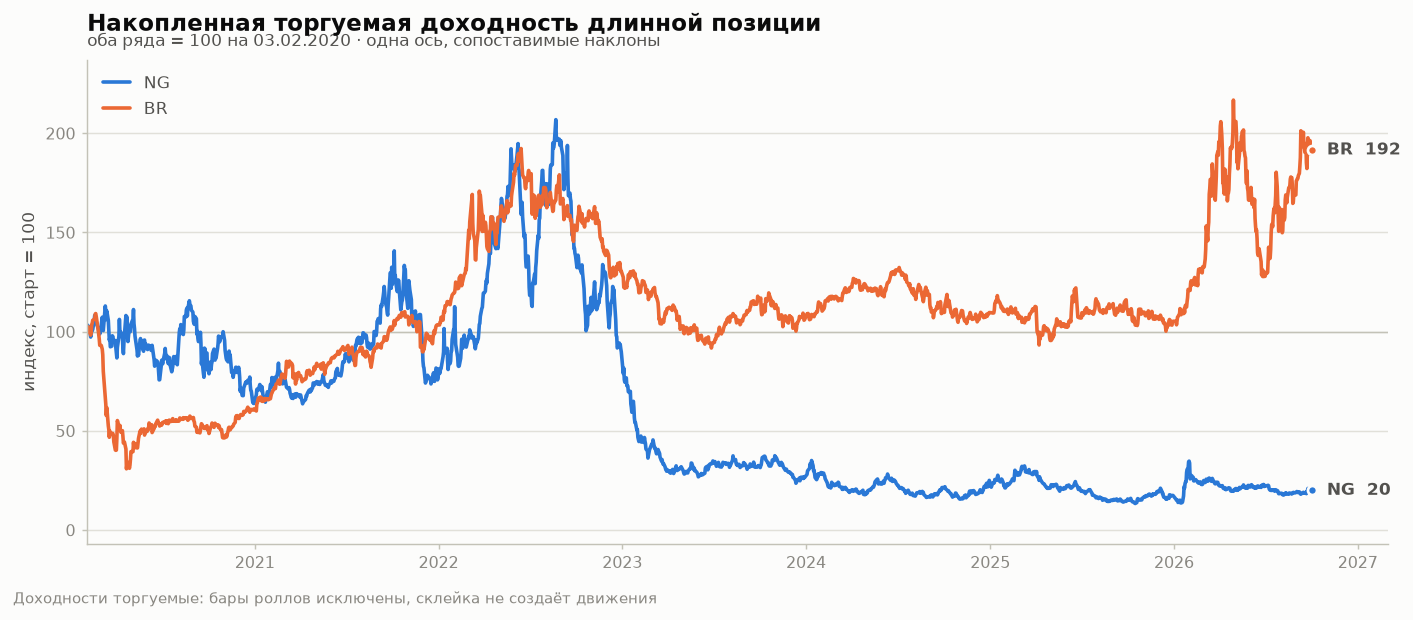

In [6]:
start = max(panels["NG"]["adjusted"].index[0], panels["BR"]["adjusted"].index[0])
common = {root: p["adjusted"]["close"].loc[start:] for root, p in panels.items()}
indexed = {root: s / float(s.iloc[0]) * 100.0 for root, s in common.items()}

fig, ax = plt.subplots(figsize=(11, 4.6))
for root, color in (("NG", SERIES_1), ("BR", SERIES_2)):
    ax.plot(indexed[root].index, indexed[root].to_numpy(), color=color, label=root)
ax.axhline(100.0, color=AXIS, linewidth=0.8, zorder=1)
frame(ax, "Накопленная торгуемая доходность длинной позиции",
      f"оба ряда = 100 на {start:%d.%m.%Y} · одна ось, сопоставимые наклоны",
      ylabel="индекс, старт = 100")
for root, color in (("NG", SERIES_1), ("BR", SERIES_2)):
    end_label(ax, indexed[root], color, text=f"{root}  {float(indexed[root].iloc[-1]):,.0f}")
legend = ax.legend(frameon=False, loc="upper left", fontsize=9.5,
                   handlelength=1.6, labelcolor=INK_2)
ax.set_xlim(start, indexed["NG"].index[-1] + pd.Timedelta(days=150))
ax.margins(y=0.10)
fig.text(0.008, -0.02, "Доходности торгуемые: бары роллов исключены, склейка не создаёт движения",
         color=MUTED, fontsize=8.5)
plt.tight_layout()
plt.show()

## 4. Чего стоит сырой ряд вендора

Сравнивать здесь надо не уровни цен, а **накопленную доходность**: вопрос в том, сколько движения
создаёт сама склейка. Оба ряда приведены к 100 на старте — сырой, со ступенями на переходах между
контрактами, и торгуемый, где эти бары исключены.

Расхождение между линиями — это не два взгляда на рынок. Это ровно та доходность, которую
изготавливают 80 переходов контанго по ~+3.8% каждый. Трендовый бэктест на сыром ряде торгует
именно её.

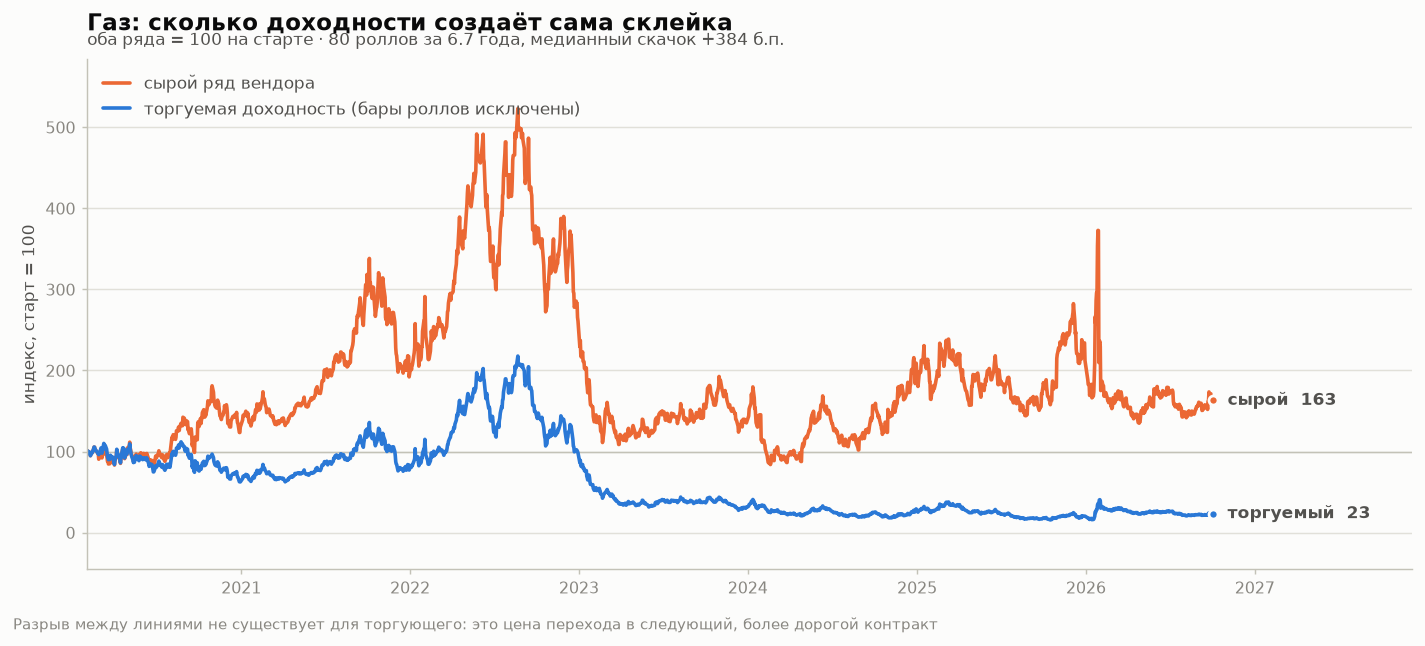

сырой ряд за период:        +63.1%
торгуемая доходность:       -76.6%
создано склейкой:           +139.7%
роллов: 80, медианный скачок +384 б.п., выше 100 б.п.: 95%


In [7]:
art = panels["NG"]["artefact"]
raw_ng = panels["NG"]["raw"]["close"]

# Накопленная доходность каждого ряда: сырого (со скачками) и торгуемого.
# Накопленная доходность каждого ряда, посчитанная на исходных часовых барах
# и прореженная до дневной для графика — чтобы подписи на линиях совпадали
# с числами под графиком бит в бит.
hourly = panels["NG"]["series"].bars["close"]
raw_curve = (hourly / float(hourly.iloc[0]) * 100.0).resample("1D").last().dropna()
tradeable = panels["NG"]["series"].tradeable_returns().fillna(0.0)
tradeable_curve = ((1.0 + tradeable).cumprod() * 100.0).resample("1D").last().dropna()

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(raw_curve.index, raw_curve.to_numpy(), color=SERIES_2, label="сырой ряд вендора")
ax.plot(tradeable_curve.index, tradeable_curve.to_numpy(), color=SERIES_1,
        label="торгуемая доходность (бары роллов исключены)")
ax.axhline(100.0, color=AXIS, linewidth=0.8, zorder=1)
years = (raw_curve.index[-1] - raw_curve.index[0]).days / 365.25
frame(ax, "Газ: сколько доходности создаёт сама склейка",
      f"оба ряда = 100 на старте · {art['n_rolls']} роллов за {years:.1f} года, "
      f"медианный скачок {art['median_gap_bps']:+.0f} б.п.",
      ylabel="индекс, старт = 100")
end_label(ax, raw_curve, SERIES_2, text=f"сырой  {float(raw_curve.iloc[-1]):,.0f}")
end_label(ax, tradeable_curve, SERIES_1, text=f"торгуемый  {float(tradeable_curve.iloc[-1]):,.0f}")
ax.legend(frameon=False, loc="upper left", fontsize=9.5, handlelength=1.6, labelcolor=INK_2)
ax.set_xlim(raw_curve.index[0], raw_curve.index[-1] + pd.Timedelta(days=430))
ax.margins(y=0.12)
fig.text(0.008, -0.02, "Разрыв между линиями не существует для торгующего: это цена перехода "
         "в следующий, более дорогой контракт", color=MUTED, fontsize=8.5)
plt.tight_layout()
plt.show()

print(f"сырой ряд за период:        {art['raw_total_return']:+.1%}")
print(f"торгуемая доходность:       {art['tradeable_total_return']:+.1%}")
print(f"создано склейкой:           {art['splice_artefact']:+.1%}")
print(f"роллов: {art['n_rolls']}, медианный скачок {art['median_gap_bps']:+.0f} б.п., "
      f"выше 100 б.п.: {art['share_above_100bps']:.0%}")

## 5. Таблица значений

Котировки на конец каждого года. График показывает форму, таблица — числа; идентичность ряда не
передаётся одним только цветом.

In [8]:
table = pd.DataFrame({
    "NG, USD/MMBtu": panels["NG"]["raw"]["close"].resample("YE").last().round(3),
    "BR, USD/bbl": panels["BR"]["raw"]["close"].resample("YE").last().round(2),
})
table.index = table.index.year
table.index.name = "год (закрытие)"
table

,"NG, USD/MMBtu","BR, USD/bbl"
год (закрытие),,
2011,NaN,107.41
2012,NaN,110.69
2013,NaN,111.10
2014,NaN,57.39
2015,NaN,36.62
2016,NaN,56.78
2017,NaN,66.51
2018,NaN,52.21
2019,NaN,68.42


---

### Что эти графики показывают — и чего не показывают

**Показывают:** реальные котировки двух инструментов (§1–2) и торгуемую доходность длинной
позиции в них (§3), в которой склейка контрактов не создаёт и не уничтожает доходность.

**Не показывают:**

* **Деньги.** NG и BR на MOEX — расчётные фьючерсы: цена в долларах, вариационная маржа в рублях
  по курсу биржи. Чтобы перейти от этих графиков к P&L, нужны множитель контракта, стоимость шага
  и ряд USD/RUB.
* **Сезонность газа.** Она живёт в форме кривой и в roll yield, а ряд по ближайшей экспирации их
  стирает. Для этого нужна панель датированных контрактов, которой вендор не даёт.
* **Повод для стратегии.** Сканер по этим рядам нашёл единственную устойчиво измеримую
  структуру — кластеризацию волатильности; направленные эффекты на часовках в 5–6 раз меньше
  одного тика. Красивый график цены не является доказательством существования edge.